# Page: `_RPGM` as a base scene, the mono map, and where tile data lives

**Recommendation: keep the mono map, split `_RPGM` into a base scene plus a map scene, and leave the painted cells on the `TileMapLayer` nodes.** Two of your three ideas are good. The third (cells in a Resource) is the one with a red flag.

![A base _RPGM scene holds only machinery; one map scene made from it adds tile layers and rooms; cells stay on TileMapLayer nodes which read a TileSet resource; splitting rooms into their own scenes is a later step; storing cells in a custom Resource is to be avoided](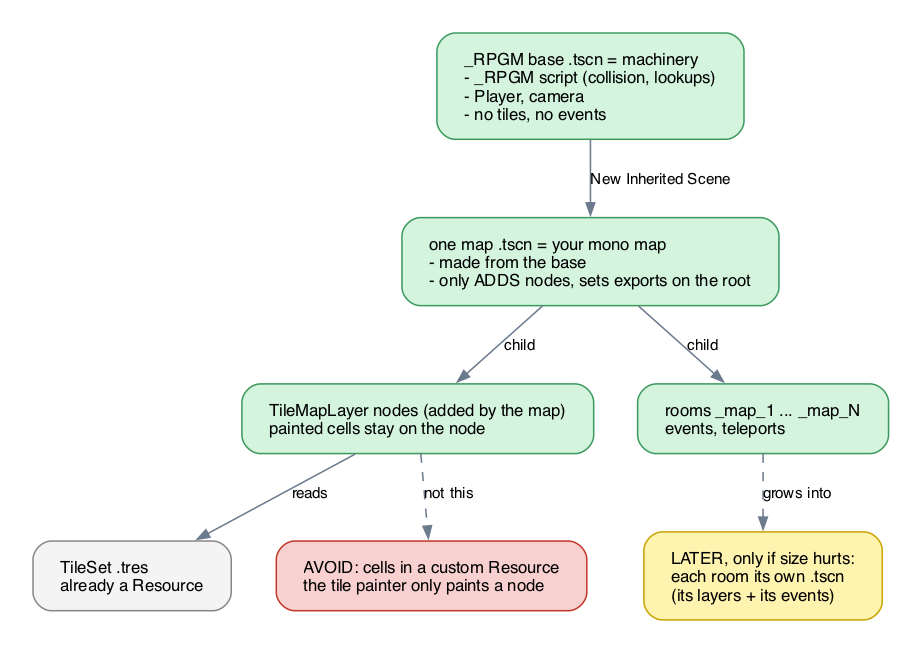)

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  rankdir=TB; nodesep=0.4; ranksep=0.55;
  node [shape=box, style="rounded,filled", fillcolor="#f4f4f4", color="#888888", fontname="Helvetica", fontsize=11];
  edge [fontname="Helvetica", fontsize=10];

  base   [label="_RPGM base .tscn = machinery\l- _RPGM script (collision, lookups)\l- Player, camera\l- no tiles, no events\l", fillcolor="#d4f4dd", color="#3c9a5f"];
  world  [label="one map .tscn = your mono map\l- made from the base\l- only ADDS nodes, sets exports on the root\l", fillcolor="#d4f4dd", color="#3c9a5f"];
  layers [label="TileMapLayer nodes (added by the map)\lpainted cells stay on the node\l", fillcolor="#d4f4dd", color="#3c9a5f"];
  rooms  [label="rooms _map_1 ... _map_N\levents, teleports\l", fillcolor="#d4f4dd", color="#3c9a5f"];
  later  [label="LATER, only if size hurts:\leach room its own .tscn\l(its layers + its events)\l", fillcolor="#fff3b0", color="#c9a400"];
  tileset [label="TileSet .tres\lalready a Resource\l"];
  custom [label="AVOID: cells in a custom Resource\lthe tile painter only paints a node\l", fillcolor="#f9d0d0", color="#c0392b"];

  base -> world [label="New Inherited Scene"];
  world -> layers [label="child"];
  world -> rooms [label="child"];
  layers -> tileset [label="reads"];
  rooms -> later [style=dashed, label="grows into"];
  layers -> custom [style=dashed, label="not this"];
}
```

</details>

| Question | Recommend | Lasting cost (not scope) | Red flag? |
|---|---|---|---|
| Keep one mono map at 5 to 10 times the size? | **Yes** | everything is loaded and in memory from boot, which matters most on web | none from the engine |
| `_RPGM` as a base `.tscn` that maps are made from? | **Yes**: base = machinery, map = content | a map made from a base is a diff stored by node path | only if a map overrides nodes that live inside the base (next row) |
| Put the tile layers in the base, painted per map? | **No**: the map adds its own layers | none | **yes**: rename a layer in the base and every map's cells for it are dropped |
| Store painted cells in a custom Resource? | **No** | two copies of the cells to keep in sync, or your own painter to maintain | **yes**: Godot's tile painter only paints a selected `TileMapLayer`; a Resource shows nothing in the editor on its own |
| Tile data in its own file anyway? | **Later**: one `.tscn` per room, holding that room's layers and events | a layer stack per room, no painting across rooms, rooms must sit on the world tile grid | none |
| Many small maps instead of one mono map? | **Not needed** | loading between maps, teleports that cross scenes, state handed over | none, just not what you like |
| **Result** | **mono map + base scene + cells on nodes** | **one map always fully loaded** | **avoid: layers in the base, cells in a Resource** |

- **Your new rule already holds for tiles.** Godot splits it the same way: the `TileSet` is the doc (a Resource, already `.tres` files here), the `TileMapLayer` is the thing that draws and collides, and the painted cells are one property on it (`tile_map_data`). A layer does things, so it is a node.
- **Why the base scene is worth it.** `_rpgm.tscn` today is both the machinery (script, Player, camera) and one game's content (9 rooms, 9 tile layers). This repo is a core for many games; a second RPGM game needs the first without the second.
- **The one rule that keeps the base safe:** a map only adds nodes and sets exports on the `_RPGM` root. Anything a map needs to vary inside the base (player start, camera limits) becomes an export on the root. That is composition via exports again.
- **Size check.** Today: 205 KB scene, about 300 nodes in the file, 9 tile layers, roughly 4,500 painted cells. At 10 times: about 2 MB, 3,000 nodes, 45,000 cells. That is small for Godot's tile renderer, which draws in chunks and skips what is off screen.
- **What grows with map size in today's code** (scope, fixable, but do it before growing):
  - `_RPGM_Player._process` calls `scripts_currently_on_map()`, a search of the whole map tree, every frame.
  - every `_RPGM_Script` node runs its own `_process` every frame, including in rooms the player is nowhere near. The event-actuator refactor removes most of this.
  - `_rebuild_collision_tiles()` searches the whole tree for movers each time anything marks collision dirty.
  - `get_base_layer()` searches the tree by name (`"L1 Base"`) on every call.
- **When to do the "later" row:** when web boot time or editor saves get slow. A room scene is also the natural unit to put to sleep while the player is elsewhere.

From reading the code and scene files: nothing was changed, run or measured, and the web boot cost at 10 times is not measured. I have not tested in 4.7 exactly how the editor reports an override whose base node was renamed; expect a warning at most.
